# Credit to...
- Frank Desueza
- Pinzhuo Xu

# Introduction to Datasets  
*Note.*   
UN = United Nations || WB = World Bank
## Data Set (Countries and Year):
- **Slums Population % <<< Target**
  - UN - 11.1.1
- Access to Drinking Water %
  - UN - 6.1.1
- Access to Sanitation %
  - UN - 6.2.1
- Access to Electricity %
  - UN - 7.1.1
  - WB - EG.ELC.ACCS.ZS
- GDP per capita
  - ~~UN - 8.1.1  (was % growth)~~
  - WB - NY.GDP.PCAP.CD
- Poverty %
  - UN - 1.1.1
- Urban Population Growth %
  - WB - SP.URB.GROW
- Population Density
  - WB - EN.POP.DNST
- Unemployment % (% of labor force)
  - UN - 8.5.2
  - ~~WB - SL.UEM.TOTL.ZS~~
- Informal Employment (% of total employment)
  - UN - 8.3.1
- PM2.5 - Particulate Matter where D 2.5 m (diameter)
  - UN - 11.6.2
  - WB - EN.ATM.PM25.MC.M3



# Imports

In [ ]:
!pip install -q aiohttp
!pip install pycountry

import asyncio
import aiohttp
import io
import numpy
import pandas as pd
import nest_asyncio
import matplotlib.pyplot as plt
import seaborn as sns

import datetime as dt
from google.colab import output

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 36.8 MB/s eta 0:00:00


# Data Collection

In [ ]:
def returnExcel(paths):
  for i in range(len(paths)):
    paths[i] = pd.read_excel(paths[i])
    print(f'Data {i} has been downloaded')

  return paths

In [ ]:
# UN DATA SETS - 1, 6, 7, 8, 11
UN = [
      'https://drive.usercontent.google.com/download?id=1_4ZGZCFS4N6jidJIsB3Ma1BOme99Rka0&export=download&authuser=0&confirm=t&uuid=4e2dd146-4b5e-4c00-8dd5-defbb4487344&at=AGN2oQ1vP8qCRBJuTDjhY36WgNzB:1774748743381'
    , 'https://drive.usercontent.google.com/download?id=1tTS6N8A2hnoDeOiy6EFCrk5qxonIpuW5&export=download&authuser=0&confirm=t&uuid=7bf6f970-755e-49d2-86ef-c563f02c03d4&at=AGN2oQ3pP_qK3NV88tijy30LD-T5:1774748772289'
    , 'https://drive.usercontent.google.com/download?id=1AER3RHXR7JQyycvu03jQBcv3xLf7_h_e&export=download&authuser=0&confirm=t&uuid=4f00caf0-02a6-4b6c-a348-c6d8fddae20b&at=AGN2oQ2rZDhBOC3iRq5xtNMtWzuV:1774748775297'
    , 'https://drive.usercontent.google.com/download?id=12l1czTWrxcfe03TvHEAVKD5WHqunC44o&export=download&authuser=0&confirm=t&uuid=45711d01-d892-417a-ada5-9ee6aa8b40f3&at=AGN2oQ12D2SZOXaSFfi1jrySnz5L:1774748791935'
    , 'https://drive.usercontent.google.com/download?id=16B1-0zOv0rzxaYvR0dqOuVYwhBrUNHYP&export=download&authuser=0&confirm=t&uuid=da10534a-1688-4038-8669-13d19fa26ccd&at=AGN2oQ2CTeonw5DUhk47fQUvR4Wn:1774748795893'
]

# WB DATA SETS
'''
    urban growth
    unemployment
    gdp per capita
    pop. density
    pm 2.5
    accessible elecricity
'''

WB = [
      'https://drive.usercontent.google.com/download?id=1ypFOwnxjmmrnzvqObHTEULfXs6HNNT1V&export=download&authuser=0&confirm=t&uuid=b92b0f0a-3946-4deb-ab6c-1fff34f85caf&at=AGN2oQ3VhwNBgKi0zoc2YwY9QB5z:1774752713926'
    , 'https://drive.usercontent.google.com/download?id=1jzgeNNGzubc6r1qSNp_LTnRNnka4RJm7&export=download&authuser=0&confirm=t&uuid=10526e87-2bdb-4aa7-94d6-91223772fdba&at=AGN2oQ1LMV_cVKBNGlg5BRE2Rylk:1774752714582'
    , 'https://drive.usercontent.google.com/download?id=1euLd0fsaBuPqDYaRGvK5HBh4fRCQeves&export=download&authuser=0&confirm=t&uuid=d49a2cde-4562-4663-949d-fb95cf587515&at=AGN2oQ0-ps_07lLO8d7iF2zHNB6E:1774752715618'
    , 'https://drive.usercontent.google.com/download?id=1n_W_DqZzM1iyXV2Q2ICv5exw0XSqR-gz&export=download&authuser=0&confirm=t&uuid=b92ca02e-6890-4e46-8b6d-f0af3bccc697&at=AGN2oQ1s74DUWlWub7-VBhNBQ5TM:1774752716600'
    , 'https://drive.usercontent.google.com/download?id=18zZuTNiwBndram_AHQgsTTJyz9oiPxOl&export=download&authuser=0&confirm=t&uuid=be681ba7-5421-4fbe-9e4e-b5f1427a9776&at=AGN2oQ2Pq18VbXX6LpF3U5fhMNd2:1774752717711'
    , 'https://drive.usercontent.google.com/download?id=1J2ZWsVp7OHo9CV7OV704j7Zspio-G5Xj&export=download&authuser=0&confirm=t&uuid=239be0c2-0ce1-4b40-8fb6-e875a0e0ee38&at=AGN2oQ15RmIFp2Ot5CRQGA-5G08F:1774752718688'
]

async def fetch_excel(session, url, sem, idx):
    async with sem:
        try:
            async with session.get(url, allow_redirects=True) as resp:
                resp.raise_for_status()
                data = await resp.read()               # raw bytes into memory
                df = pd.read_excel(io.BytesIO(data))   # BytesIO acts like a file path
                print(f"  ✓ [{idx}] {df.shape[0]} rows × {df.shape[1]} cols")
                return df
        except Exception as e:
            print(f"  ✗ [{idx}] {e}")
            return None

async def main(urls, max_concurrent=5):
    sem = asyncio.Semaphore(max_concurrent)
    async with aiohttp.ClientSession() as session:
        tasks = [fetch_excel(session, url, sem, i) for i, url in enumerate(urls)]
        return await asyncio.gather(*tasks)

# Colab: await directly
UNdfs = await main(UN, max_concurrent=len(UN))
WBdfs = await main(WB, max_concurrent=len(WB))

# Each df is independent — or combine them all into one:
combinedUN = pd.concat([df for df in UNdfs if df is not None], ignore_index=True)
combinedWB = [df for df in WBdfs if df is not None]

display(combinedUN)
display(combinedWB)

  ✓ [2] 18825 rows × 27 cols
  ✓ [0] 24260 rows × 24 cols
  ✓ [4] 16974 rows × 27 cols
  ✓ [1] 45364 rows × 27 cols
  ✓ [3] 78144 rows × 27 cols
  ✓ [5] 266 rows × 70 cols
  ✓ [0] 266 rows × 70 cols
  ✓ [1] 266 rows × 70 cols
  ✓ [4] 266 rows × 70 cols
  ✓ [2] 266 rows × 70 cols
  ✓ [3] 266 rows × 70 cols


,Goal,Target,Indicator,SeriesCode,SeriesDescription,GeoAreaCode,GeoAreaName,TimePeriod,Value,Time_Detail,...,Age,Location,Nature,Observation Status,Reporting Type,Sex,Units,Activity,Cities,Disability status
0,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,1,World,2000,36.30000,2000,...,ALLAGE,ALLAREA,N,NaN,G,BOTHSEX,PERCENT,NaN,NaN,NaN
1,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,1,World,2001,35.30000,2001,...,ALLAGE,ALLAREA,N,NaN,G,BOTHSEX,PERCENT,NaN,NaN,NaN
2,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,1,World,2002,33.80000,2002,...,ALLAGE,ALLAREA,N,NaN,G,BOTHSEX,PERCENT,NaN,NaN,NaN
3,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,1,World,2003,32.30000,2003,...,ALLAGE,ALLAREA,N,NaN,G,BOTHSEX,PERCENT,NaN,NaN,NaN
4,1,1.1,1.1.1,SI_POV_DAY1,Proportion of population below international p...,1,World,2004,30.40000,2004,...,ALLAGE,ALLAREA,N,NaN,G,BOTHSEX,PERCENT,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183562,11,11.6,11.6.2,EN_ATM_PM25,Annual mean levels of fine particulate matter ...,894,Zambia,2019,16.89670,2019,...,NaN,ALLAREA,E,NaN,G,NaN,mgr/m^3,NaN,NaN,NaN
183563,11,11.6,11.6.2,EN_ATM_PM25,Annual mean levels of fine particulate matter ...,894,Zambia,2019,17.29497,2019,...,NaN,TSUB,E,NaN,G,NaN,mgr/m^3,NaN,NaN,NaN
183564,11,11.6,11.6.2,EN_ATM_PM25,Annual mean levels of fine particulate matter ...,894,Zambia,2019,19.43367,2019,...,NaN,CITY,E,NaN,G,NaN,mgr/m^3,NaN,NaN,NaN
183565,11,11.6,11.6.2,EN_ATM_PM25,Annual mean levels of fine particulate matter ...,894,Zambia,2019,16.10123,2019,...,NaN,RURAL,E,NaN,G,NaN,mgr/m^3,NaN,NaN,NaN


[                    Country Name Country Code  \
 0                          Aruba          ABW   
 1    Africa Eastern and Southern          AFE   
 2                    Afghanistan          AFG   
 3     Africa Western and Central          AFW   
 4                         Angola          AGO   
 ..                           ...          ...   
 261                       Kosovo          XKX   
 262                  Yemen, Rep.          YEM   
 263                 South Africa          ZAF   
 264                       Zambia          ZMB   
 265                     Zimbabwe          ZWE   
 
                          Indicator Name Indicator Code  1960      1961  \
 0    Urban population growth (annual %)    SP.URB.GROW   NaN  1.269021   
 1    Urban population growth (annual %)    SP.URB.GROW   NaN  4.165655   
 2    Urban population growth (annual %)    SP.URB.GROW   NaN  5.197002   
 3    Urban population growth (annual %)    SP.URB.GROW   NaN  5.777952   
 4    Urban population 

## Cleaning Up United Nations Data (Country, Year, Value)

In [ ]:
def sepByIndicator(db, indic):
  codes = db['Indicator']
  start = codes[0]

  indices = []
  for i in range(1, len(codes)):
    if start != codes[i] and str(codes[i]) != 'nan':
      start = codes[i]
      indices.append(i)

  return indices

In [ ]:
dic = {
        'Indicator': combinedUN['Indicator'],
        'Country': combinedUN['GeoAreaName'],
        'Year': combinedUN['TimePeriod'],
        'Value': combinedUN['Value']
      }

UNdata = pd.DataFrame(dic)

splitBy = [ '1.1.1',
            '6.1.1', '6.2.1',
            '7.1.1',
            '8.1.1', '8.3.1', '8.5.2',
            '11.1.1', '11.6.2' ]

indices = sepByIndicator(combinedUN, splitBy)

UNdfs = {}

start = 0

for i in range(len(indices)):
  UNdfs.update({splitBy[i] : UNdata[start:indices[i]].drop(columns=['Indicator'])})
  start = indices[i]

UNdfs.update({splitBy[-1] : UNdata[indices[-1]:].drop(columns=['Indicator'])})
UNdfs

{'1.1.1':       Country  Year  Value
 0       World  2000  36.30
 1       World  2001  35.30
 2       World  2002  33.80
 3       World  2003  32.30
 4       World  2004  30.40
 ...       ...   ...    ...
 24255  Zambia  2022  70.12
 24256  Zambia  2022  69.00
 24257  Zambia  2022  68.81
 24258  Zambia  2022  69.76
 24259  Zambia  2022  65.94
 
 [24260 rows x 3 columns],
 '6.1.1':       Country  Year      Value
 24260   World  2000  83.497620
 24261   World  2000  41.938976
 24262   World  2000  61.261635
 24263   World  2001  61.494740
 24264   World  2001  42.104755
 ...       ...   ...        ...
 35035  Zambia  2020  51.390862
 35036  Zambia  2021  51.094543
 35037  Zambia  2022  50.794746
 35038  Zambia  2023  50.491463
 35039  Zambia  2024  50.184700
 
 [10780 rows x 3 columns],
 '6.2.1':       Country  Year      Value
 35040   World  2000   4.543590
 35041   World  2000  21.052498
 35042   World  2000  35.357925
 35043   World  2001  20.440607
 35044   World  2001   4.408332
 ..

## Cleaning Up World Bank Data (Country, Year, Value)

In [ ]:
def returnCleanWB(db):
  years = list(db)[4:]
  countries = list(db['Country Name'])
  indicators = list(db['Indicator Code'])

  tmpC = []
  for country in countries:
    tmpC += [country] * len(years)

  tmpY = []
  for year in years:
    tmpY += [int(year)] * len(countries)

  values = []
  for i in range(len(years)):
    values += list(db[years[i]])

  return pd.DataFrame({
        'Indicator': indicators * len(years),
        'Country': countries * len(years),
        'Year': tmpY,
        'Value': values
      })

In [ ]:
WBdata = []

for i in range(len(combinedWB)):
  WBdata.append(returnCleanWB(combinedWB[i]))

WBdfs = {}

indices = [WBdata[i]['Indicator'][0] for i in range(len(WBdata)) ]

for i in range(len(indices)):
  WBdfs.update({indices[i] : WBdata[i].drop(columns=['Indicator'])})

WBdfs['EG.ELC.ACCS.ZS']

,Country,Year,Value
0,Aruba,1960,NaN
1,Africa Eastern and Southern,1960,NaN
2,Afghanistan,1960,NaN
3,Africa Western and Central,1960,NaN
4,Angola,1960,NaN
...,...,...,...
17551,Kosovo,2025,NaN
17552,"Yemen, Rep.",2025,NaN
17553,South Africa,2025,NaN
17554,Zambia,2025,NaN


## Creation of Master List

In [ ]:
def returnAll(data, find):
  tmp = []

  for i in data[0].keys():
    for get in data[0][i][find]:
      if get not in tmp:
       tmp.append(get)

  for i in data[1].keys():
    for get in data[1][i][find]:
      if get not in tmp:
        tmp.append(get)

  return tmp

def blankList(size):
  L = []
  for i in range(size):
    L.append(None)
  return L

import pycountry

def get_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except:
        return None

### Preperation

In [ ]:
# Makes all countries into their iso3 ID
for key, df in WBdfs.items():
  if isinstance(df, pd.DataFrame) and 'Country' in df.columns:
    WBdfs[key]['Country'] = df['Country'].apply(get_iso3)
  else:
    print(f"Skipping {key}: not a DataFrame or missing 'Country' column")

for key, df in UNdfs.items():
  if isinstance(df, pd.DataFrame) and 'Country' in df.columns:
    UNdfs[key]['Country'] = df['Country'].apply(get_iso3)
  else:
    print(f"Skipping {key}: not a DataFrame or missing 'Country' column")

# takes out all None for Countries
for key in WBdfs.keys():
  WBdfs[key].dropna(inplace=True)

for key in UNdfs.keys():
  UNdfs[key].dropna(inplace=True)


In [ ]:
countries = returnAll((UNdfs, WBdfs), 'Country')
years     = sorted(list(returnAll((UNdfs, WBdfs), 'Year')))[:]

sources = [
    (UNdfs['11.1.1'],              'Slums'),
    (UNdfs['6.1.1'],               'Access To Water'),
    (UNdfs['6.2.1'],               'Access To Sanitation'),
    (UNdfs['7.1.1'],               'Access to ElectricityUN'),
    (WBdfs['EG.ELC.ACCS.ZS'],      'Access to ElectricityWB'),
   # (UNdfs['8.1.1'],               'GDP per capitaUN'),
    (WBdfs['NY.GDP.PCAP.CD'],      'GDP per capitaWB'),
    (UNdfs['1.1.1'],               'Poverty %'),
    (WBdfs['SP.URB.GROW'],         'Urban Population Growth %'),
    (WBdfs['EN.POP.DNST'],         'Population Density'),
    (UNdfs['8.5.2'],               'Unemployment %'),
   # (WBdfs['SL.UEM.TOTL.ZS'],      'Unemployment %WB'),
    (UNdfs['8.3.1'],               'Informal Employment'),
    (UNdfs['11.6.2'],              'PM 2.5 UN'),
    (WBdfs['EN.ATM.PM25.MC.M3'],   'PM 2.5 WB'),
]

In [ ]:
Dict = {}
tmp = []

for i in countries:
  for _ in years:
    tmp.append(i)

Dict.update({'Country' : tmp})
Dict.update({'Year' : years * (len(Dict['Country'])//len(years))})

size = len(Dict['Country'])

for tup in sources:
  name = tup[1]

  Dict.update({name:blankList(size)})

len(Dict['Country']), len(Dict['Year'])

(14982, 14982)

In [ ]:
Dict.keys()

dict_keys(['Country', 'Year', 'Slums', 'Access To Water', 'Access To Sanitation', 'Access to ElectricityUN', 'Access to ElectricityWB', 'GDP per capitaWB', 'Poverty %', 'Urban Population Growth %', 'Population Density', 'Unemployment %', 'Informal Employment', 'PM 2.5 UN', 'PM 2.5 WB'])

### Finalization

In [ ]:
nest_asyncio.apply()  # allows nested event loops in Colab

async def process_source(source, Dict, size):
    data, key = source

    for row in range(len(data)):
        tmp = data.iloc[row].tolist()
        country = tmp[0]
        year    = tmp[1]
        value   = tmp[2]

        for i in range(size):
            try:
                if Dict['Country'][i] == country and Dict['Year'][i] == year:
                    Dict[key][i] = value
                    break

            except ValueError as e:
                print(Dict['Country'], country, Dict['Year'], year)
                break

        await asyncio.sleep(0)

    print(f'✅ Task finished: {key}')

async def main():
    tasks = [process_source(source, Dict, size) for source in sources]
    await asyncio.gather(*tasks)
    print('🎉 All tasks finished')

asyncio.run(main())  # works fine now with nest_asyncio

✅ Task finished: Slums
✅ Task finished: PM 2.5 WB
✅ Task finished: Access to ElectricityWB
✅ Task finished: Access To Water
✅ Task finished: GDP per capitaWB
✅ Task finished: PM 2.5 UN
✅ Task finished: Population Density
✅ Task finished: Urban Population Growth %
✅ Task finished: Access to ElectricityUN
✅ Task finished: Informal Employment
✅ Task finished: Poverty %
✅ Task finished: Access To Sanitation
✅ Task finished: Unemployment %
🎉 All tasks finished


In [ ]:
master = pd.DataFrame(Dict)
master.keys()

Index(['Country', 'Year', 'Slums', 'Access To Water', 'Access To Sanitation',
       'Access to ElectricityUN', 'Access to ElectricityWB',
       'GDP per capitaWB', 'Poverty %', 'Urban Population Growth %',
       'Population Density', 'Unemployment %', 'Informal Employment',
       'PM 2.5 UN', 'PM 2.5 WB'],
      dtype='object')

In [ ]:
master

,Country,Year,Slums,Access To Water,Access To Sanitation,...,Population Density,Unemployment %,Informal Employment,PM 2.5 UN,PM 2.5 WB
0,ALB,1960,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN
1,ALB,1961,NaN,NaN,NaN,...,60.576642,NaN,NaN,NaN,NaN
2,ALB,1962,NaN,NaN,NaN,...,62.456898,NaN,NaN,NaN,NaN
3,ALB,1963,NaN,NaN,NaN,...,64.329234,NaN,NaN,NaN,NaN
4,ALB,1964,NaN,NaN,NaN,...,66.209307,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
14977,NLD,2021,NaN,NaN,NaN,...,520.731928,NaN,NaN,NaN,NaN
14978,NLD,2022,NaN,NaN,NaN,...,525.719691,NaN,NaN,NaN,NaN
14979,NLD,2023,NaN,NaN,NaN,...,530.950906,NaN,NaN,NaN,NaN
14980,NLD,2024,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN


## Modifications

In [ ]:
master[['Access to ElectricityUN', 'Access to ElectricityWB']].corr()

,Access to ElectricityUN,Access to ElectricityWB
Access to ElectricityUN,1.000000,0.862859
Access to ElectricityWB,0.862859,1.000000


In [ ]:
master[['PM 2.5 UN', 'PM 2.5 WB']].corr()

,PM 2.5 UN,PM 2.5 WB
PM 2.5 UN,1.000000,0.852923
PM 2.5 WB,0.852923,1.000000


In [ ]:
master['Electricity'] = master['Access to ElectricityUN'].combine_first(master['Access to ElectricityWB'])
master.drop(columns=['Access to ElectricityUN', 'Access to ElectricityWB'], inplace=True)

master['PM 2.5'] = master['PM 2.5 UN'].combine_first(master['PM 2.5 WB'])
master.drop(columns=['PM 2.5 UN', 'PM 2.5 WB'], inplace=True)

df = master.rename(columns={'GDP per capitaWB':'GDP per capita'})

# Data Analysis

In [ ]:
def find_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[column] < Q1 - 1.5* IQR) | (df[column] > Q3 + 1.5 * IQR)]
    return outliers

# GDP Per Capita Outlier
outliers_gdp = find_outliers_iqr(df, 'GDP per capita')
print(outliers_gdp[['Country','Year','GDP per capita']])

# Poverty Outlier
outliers_poverty = find_outliers_iqr(df, 'Poverty %')
print(outliers_poverty[['Country','Year','Poverty %']])

# Urban Pop Growth Outlier
outliers_upg = find_outliers_iqr(df, 'Urban Population Growth %')
print(outliers_upg[['Country','Year','Urban Population Growth %']])

# Population Density Outlier
outliers_pd = find_outliers_iqr(df, 'Population Density')
print(outliers_pd[['Country','Year','Population Density']])

# Unemployment Outlier
outliers_unemp = find_outliers_iqr(df, 'Unemployment %')
print(outliers_unemp[['Country','Year','Unemployment %']])

# Electricity Outlier
outliers_electricity = find_outliers_iqr(df, 'Electricity')
print(outliers_electricity[['Country','Year','Electricity']])

# PM2.5 Outlier
outliers_pm = find_outliers_iqr(df, 'PM 2.5')
print(outliers_pm[['Country','Year','PM 2.5']])

      Country  Year  GDP per capita
367       AUS  1997    23683.494896
373       AUS  2003    23757.589847
374       AUS  2004    30886.050095
375       AUS  2005    34535.207271
376       AUS  2006    36658.824348
...       ...   ...             ...
14976     NLD  2020    53467.927741
14977     NLD  2021    60141.988091
14978     NLD  2022    59123.318556
14979     NLD  2023    63515.603078
14980     NLD  2024    67520.421896

[1342 rows x 3 columns]
      Country  Year  Poverty %
172       AGO  2000   27.00000
180       AGO  2008   22.10000
190       AGO  2018   33.23289
502       BGD  2000   37.18000
507       BGD  2005   26.94000
...       ...   ...        ...
10472     ZMB  2004   68.90000
10474     ZMB  2006   72.00000
10478     ZMB  2010   66.22000
10483     ZMB  2015   60.41000
10490     ZMB  2022   65.94000

[256 rows x 3 columns]
      Country  Year  Urban Population Growth %
150       AGO  1978                   8.976108
151       AGO  1979                   8.959842
152   

## heatmap

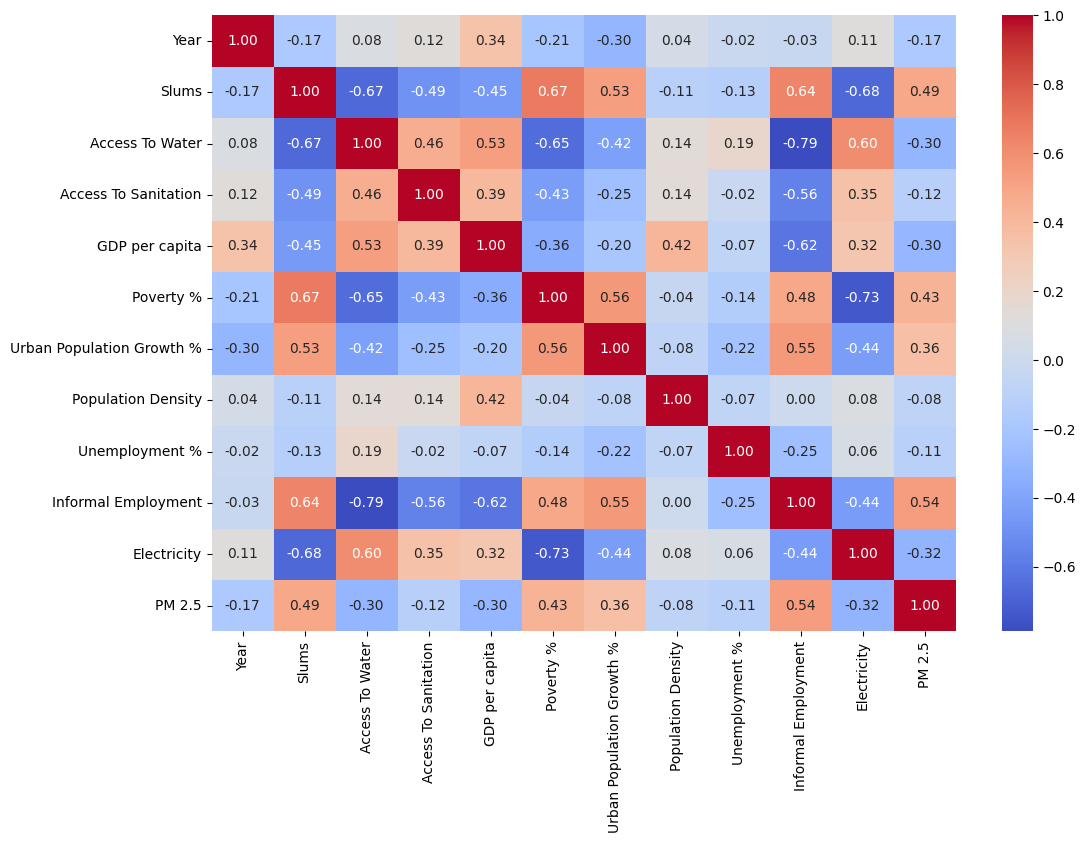

In [ ]:
#bivariate relation
numeric_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(12,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

## logarithm

In [ ]:
#log transform for skewed
import numpy as np

df['GDP_per_capita_log'] = np.log1p(df['GDP per capita'])
df['PM25_log'] = np.log1p(df['PM 2.5'])
df['Pop_density_log'] = np.log1p(df['Population Density'])

## scatter and other plots

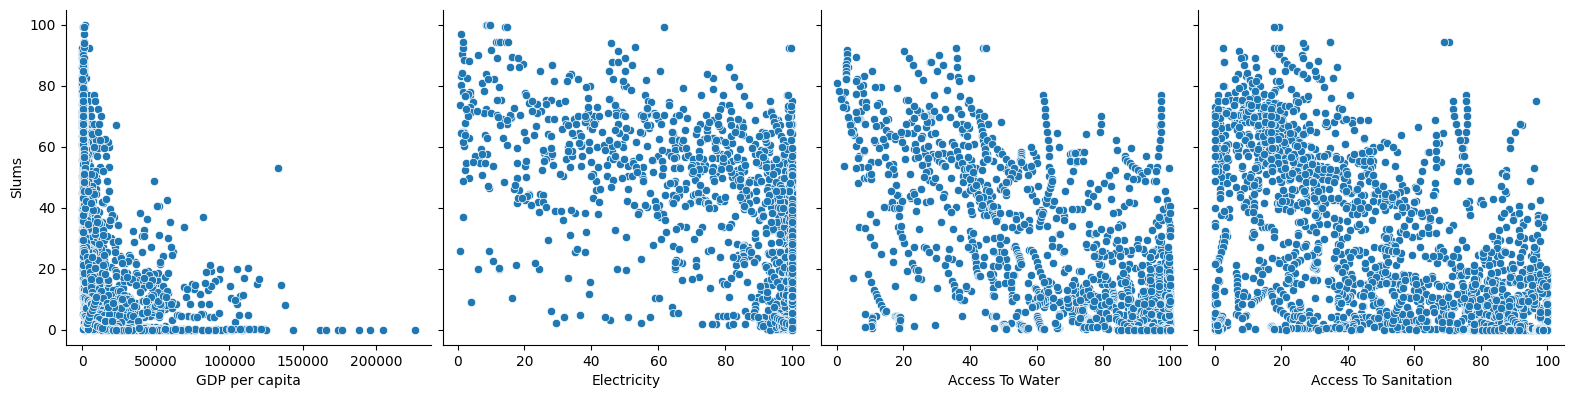

In [ ]:
# relation of slums and predictor
sns.pairplot(df, x_vars=['GDP per capita', 'Electricity', 'Access To Water', 'Access To Sanitation'],
                 y_vars='Slums', height=4, aspect=1, kind='scatter')
plt.show()

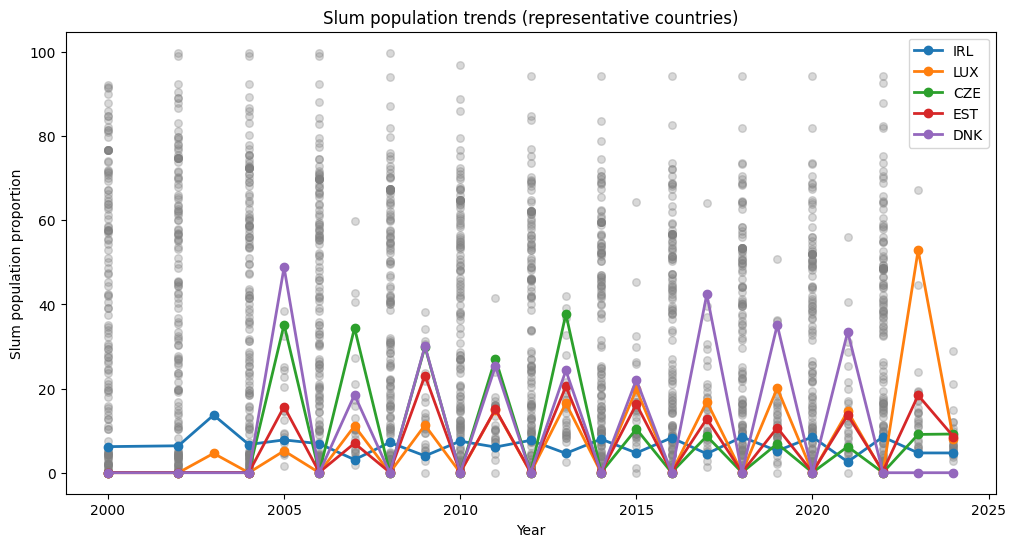

In [ ]:
#trends over time
df_slum = df[df['Slums'].notnull()]

data_counts = df_slum.groupby('Country')['Year'].count().sort_values(ascending=False)

top_countries = data_counts.head(5).index.tolist()

plt.figure(figsize=(12,6))

plt.scatter(df_slum['Year'], df_slum['Slums'], color='gray', alpha=0.3, s=30)

for c in top_countries:
    subset = df_slum[df_slum['Country'] == c]
    plt.plot(subset['Year'], subset['Slums'], marker='o', linewidth=2, label=c)

plt.xlabel("Year")
plt.ylabel("Slum population proportion")
plt.title("Slum population trends (representative countries)")
plt.legend()
plt.show()

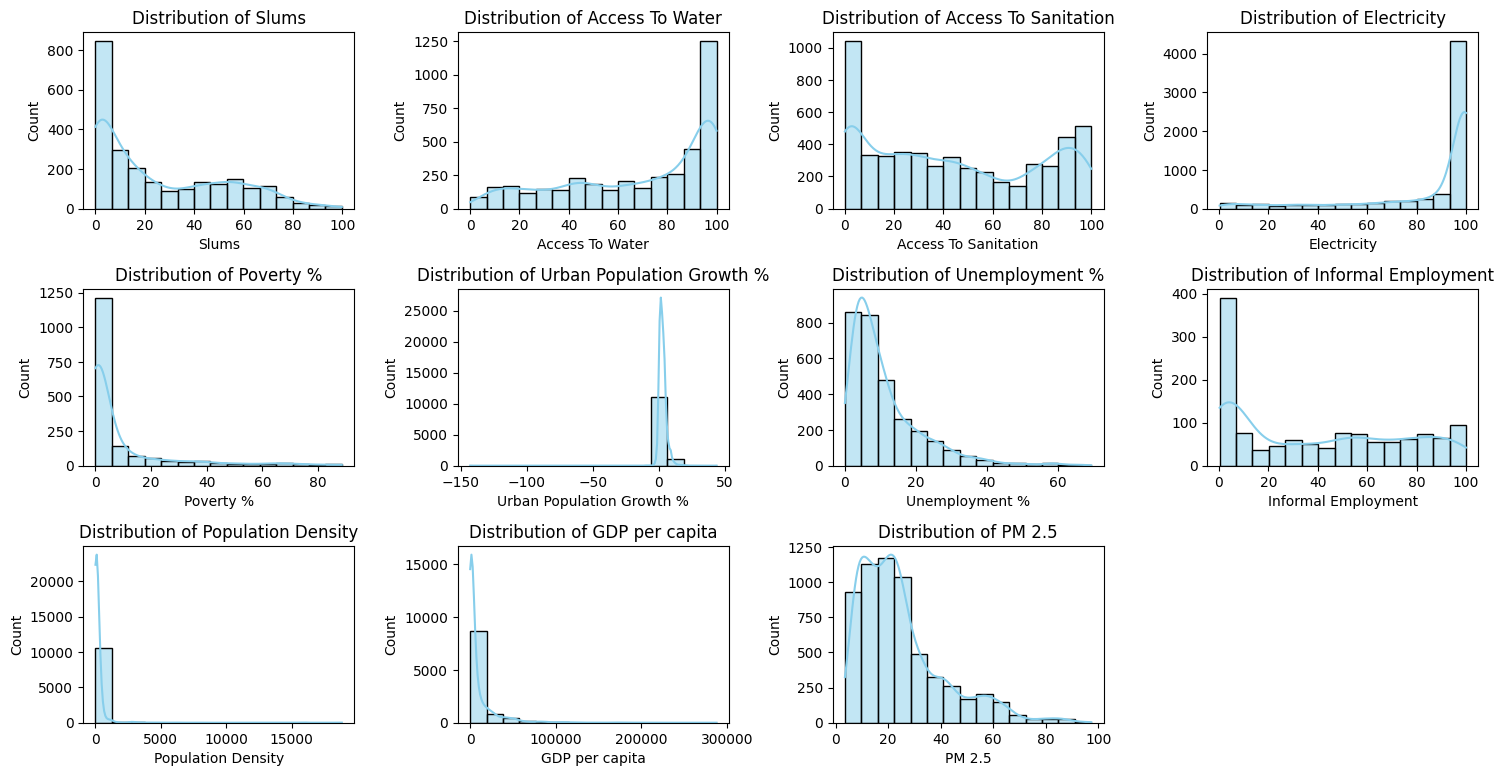

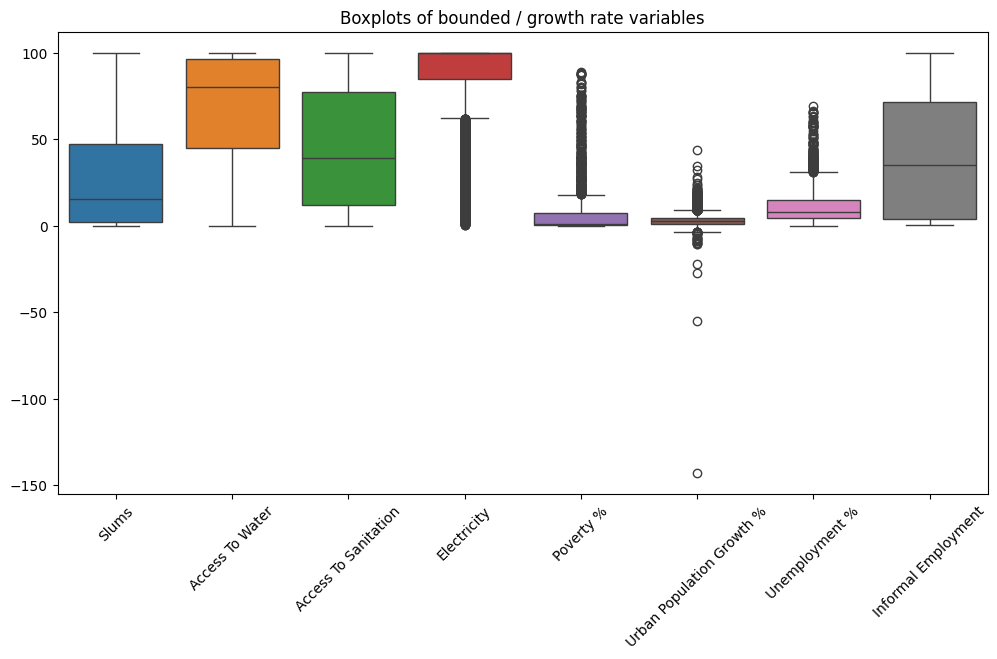

In [ ]:
# List of bounded / categorical / growth rate variables
bounded_vars = ['Slums', 'Access To Water', 'Access To Sanitation', 'Electricity', 'Poverty %', 'Urban Population Growth %', 'Unemployment %', 'Informal Employment', 'Population Density', 'GDP per capita', 'PM 2.5']

plt.figure(figsize=(15,10))

# Loop over variables and create histograms
for i, var in enumerate(bounded_vars):
    plt.subplot(4, 4, i+1)  # 3x3 grid
    sns.histplot(df[var].dropna(), bins=15, kde=True, color='skyblue')
    plt.title(f'Distribution of {var}')
    plt.xlabel(var)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()


# boxplots to check for outliers in these variables
plt.figure(figsize=(12,6))
sns.boxplot(data=df[bounded_vars[:-3]])
plt.xticks(rotation=45)
plt.title("Boxplots of bounded / growth rate variables")
plt.show()

In [ ]:
df.keys()

Index(['Country', 'Year', 'Slums', 'Access To Water', 'Access To Sanitation',
       'GDP per capita', 'Poverty %', 'Urban Population Growth %',
       'Population Density', 'Unemployment %', 'Informal Employment',
       'Electricity', 'PM 2.5', 'GDP_per_capita_log', 'PM25_log',
       'Pop_density_log'],
      dtype='object')

# Machine Learning
  1. Random Forest
  2. Gradient Boosting (sklearn)
  3. XGBoost

__Returns the Best Model__

Rows with known target: 2,413
Feature matrix shape after imputation: (2413, 4)
Split → Train: 1930 | Test: 483

── 5-Fold Cross-Validation (on training set) ─────────────────────────
  Random Forest           CV R² = 0.7036 ± 0.0141
  Gradient Boosting       CV R² = 0.6935 ± 0.0103
  XGBoost                 CV R² = 0.6923 ± 0.0150

── Test Set Metrics ──────────────────────────────────────────────────
  Random Forest           MAE=10.3213  RMSE=14.3613  R²=0.7026
  Gradient Boosting       MAE=10.4654  RMSE=14.2024  R²=0.7091
  XGBoost                 MAE=10.7363  RMSE=14.4882  R²=0.6973

★ Best model: Gradient Boosting  (R² = 0.7091)


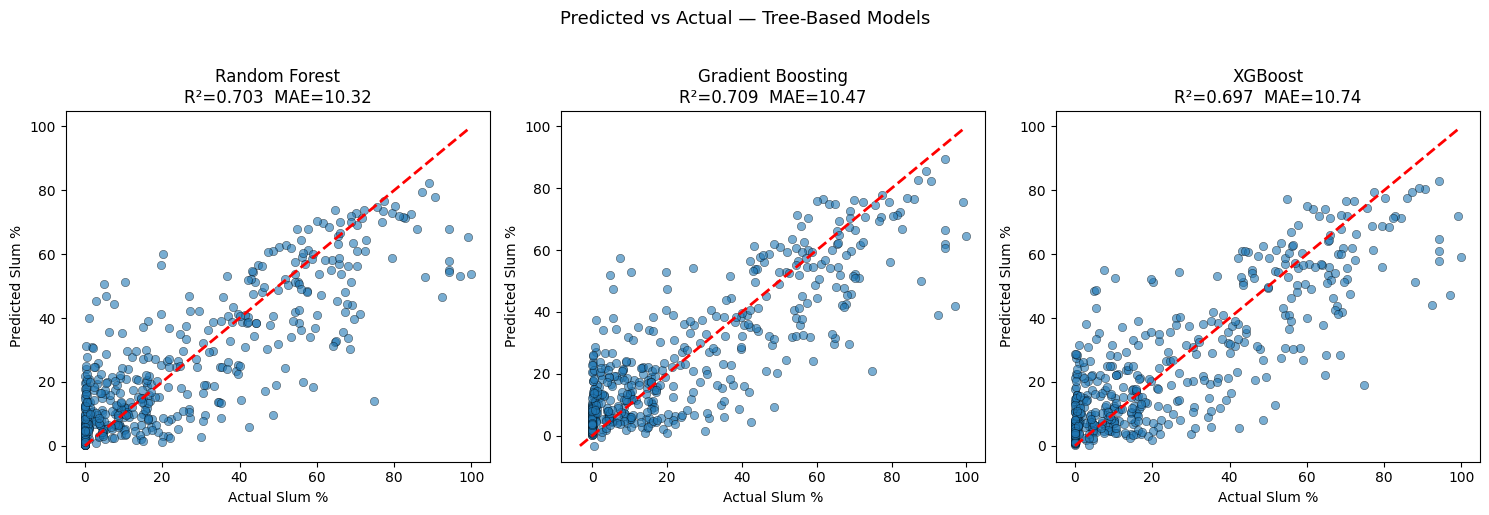

Plot saved → predicted_vs_actual_trees.png


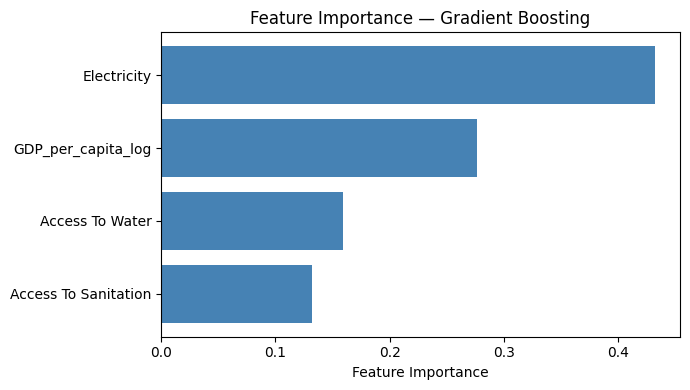

Feature importance plot saved → feature_importance.png

Sample input    : {'Access To Water': np.float64(85.0), 'Access To Sanitation': np.float64(70.0), 'Electricity': np.float64(60.0), 'GDP_per_capita_log': np.float64(2500.0)}
Predicted Slum %: 35.46%

Best model (Gradient Boosting) saved → best_slum_tree_model.pkl
Imputer saved → slum_knn_imputer.pkl


In [ ]:
"""
Slum Population Prediction — Tree-Based Ensemble Models
========================================================
Features : Access To Water, Access To Sanitation, Electricity, GDP per capita
Target   : Slums (slum population %)

Trains three models and picks the best one:
  1. Random Forest
  2. Gradient Boosting (sklearn)
  3. XGBoost

Dependencies:
    pip install xgboost scikit-learn pandas numpy joblib matplotlib
"""

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42

# =============================================================================
# 1. LOAD DATA
# =============================================================================
# Replace with your actual data source:
#   df = pd.read_csv("your_data.csv")
#   df = pd.read_excel("your_data.xlsx")
#   df = your_existing_dataframe   ← if running inside a notebook

#df = pd.read_csv("your_data.csv")   # <── change this line

# =============================================================================
# 2. DEFINE FEATURES AND TARGET
# =============================================================================
FEATURE_COLS = [
    "Access To Water",
    "Access To Sanitation",
    "Electricity",
    "GDP_per_capita_log",
]

TARGET_COL = "Slums"

# =============================================================================
# 3. CLEAN — keep only rows where the TARGET is known
#            use KNNImputer to fill missing feature values (better than dropping)
# =============================================================================
df_model = df[FEATURE_COLS + [TARGET_COL]].dropna(subset=[TARGET_COL])

print(f"Rows with known target: {len(df_model):,}")

# Impute missing features with KNN (5 nearest neighbours)
imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(df_model[FEATURE_COLS])
X = pd.DataFrame(X_imputed, columns=FEATURE_COLS).values
y = df_model[TARGET_COL].values

print(f"Feature matrix shape after imputation: {X.shape}")

# =============================================================================
# 4. TRAIN / TEST SPLIT  (80 / 20)
# =============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f"Split → Train: {len(X_train)} | Test: {len(X_test)}")

# =============================================================================
# 5. DEFINE MODELS
# =============================================================================
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=SEED,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=SEED,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=SEED,
        verbosity=0,
    ),
}

# =============================================================================
# 6. CROSS-VALIDATION + TEST EVALUATION
# =============================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}

print("\n── 5-Fold Cross-Validation (on training set) ─────────────────────────")
for name, model in models.items():
    cv_scores = cross_val_score(
        model, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1
    )
    print(f"  {name:22s}  CV R² = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

print("\n── Test Set Metrics ──────────────────────────────────────────────────")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    results[name] = {"model": model, "y_pred": y_pred, "MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"  {name:22s}  MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}")

# =============================================================================
# 7. PICK BEST MODEL BY R²
# =============================================================================
best_name = max(results, key=lambda k: results[k]["R2"])
best      = results[best_name]
print(f"\n★ Best model: {best_name}  (R² = {best['R2']:.4f})")

# =============================================================================
# 8. PLOT — Predicted vs Actual (all three models side by side)
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, res) in zip(axes, results.items()):
    ax.scatter(y_test, res["y_pred"], alpha=0.6, edgecolors="k", linewidths=0.4)
    lims = [min(y_test.min(), res["y_pred"].min()),
            max(y_test.max(), res["y_pred"].max())]
    ax.plot(lims, lims, "r--", lw=2)
    ax.set_title(f"{name}\nR²={res['R2']:.3f}  MAE={res['MAE']:.2f}")
    ax.set_xlabel("Actual Slum %")
    ax.set_ylabel("Predicted Slum %")

plt.suptitle("Predicted vs Actual — Tree-Based Models", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("predicted_vs_actual_trees.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved → predicted_vs_actual_trees.png")

# =============================================================================
# 9. FEATURE IMPORTANCE — best model
# =============================================================================
best_model = best["model"]

if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
else:
    # Permutation importance fallback
    perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=SEED)
    importances = perm.importances_mean

fi_df = pd.DataFrame({"Feature": FEATURE_COLS, "Importance": importances})
fi_df = fi_df.sort_values("Importance", ascending=True)

plt.figure(figsize=(7, 4))
plt.barh(fi_df["Feature"], fi_df["Importance"], color="steelblue")
plt.xlabel("Feature Importance")
plt.title(f"Feature Importance — {best_name}")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
print("Feature importance plot saved → feature_importance.png")

# =============================================================================
# 10. PREDICT ON NEW DATA
# =============================================================================
# [Access To Water, Access To Sanitation, Electricity, GDP per capita]
new_sample = np.array([[85.0, 70.0, 60.0, 2500.0]])
prediction = best_model.predict(new_sample)[0]

print(f"\nSample input    : {dict(zip(FEATURE_COLS, new_sample[0]))}")
print(f"Predicted Slum %: {prediction:.2f}%")

# =============================================================================
# 11. SAVE BEST MODEL AND IMPUTER
# =============================================================================
joblib.dump(best_model, "best_slum_tree_model.pkl")
joblib.dump(imputer,    "slum_knn_imputer.pkl")
print(f"\nBest model ({best_name}) saved → best_slum_tree_model.pkl")
print("Imputer saved → slum_knn_imputer.pkl")

# =============================================================================
# 12. HOW TO RELOAD AND USE LATER
# =============================================================================
# model   = joblib.load("best_slum_tree_model.pkl")
# imputer = joblib.load("slum_knn_imputer.pkl")
# new_X   = imputer.transform([[85.0, 70.0, 60.0, 2500.0]])
# print(model.predict(new_X))